# Prédiction de la réponse à une campagne marketing

Projet de data science de bout en bout : à partir du profil et de l'historique d'achats d'un client, **prédire s'il acceptera l'offre de la dernière campagne marketing**, puis restituer le résultat dans un **dashboard interactif Streamlit** (fichier `app.py` du dépôt).

**Dataset** : [Marketing Campaign (Kaggle)](https://www.kaggle.com/datasets/rodsaldanha/arketing-campaign/data) — 2 240 clients d'une entreprise, 29 colonnes.

## Contexte et objectif

Un modèle de réponse peut rendre une campagne marketing plus efficace : en contactant en priorité les clients les plus susceptibles d'accepter l'offre, on augmente le nombre de réponses ou on réduit les dépenses de la campagne.

L'objectif est de **prédire la variable `Response`** (1 si le client a accepté l'offre de la dernière campagne, 0 sinon) et d'identifier **quelles caractéristiques des clients expliquent cette réponse**.

## Variables du dataset

| Variable | Description |
|---|---|
| `Response` (**cible**) | 1 si le client a accepté l'offre de la dernière campagne, 0 sinon |
| `AcceptedCmp1` à `AcceptedCmp5` | 1 si le client a accepté l'offre lors de la campagne 1 à 5 |
| `Complain` | 1 si le client s'est plaint au cours des 2 dernières années |
| `Dt_Customer`, `Year_Birth` | date d'inscription du client, année de naissance |
| `Education`, `Marital_Status` | niveau d'études, situation maritale |
| `Kidhome`, `Teenhome` | nombre de jeunes enfants et d'adolescents au foyer |
| `Income` | revenu annuel du foyer |
| `Recency` | nombre de jours depuis le dernier achat |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | montants dépensés en vin, fruits, viande, poisson, produits sucrés et produits « gold » au cours des 2 dernières années |
| `NumDealsPurchases`, `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | nombre d'achats avec remise, via le site web, par catalogue, en magasin |
| `NumWebVisitsMonth` | nombre de visites du site web au cours du dernier mois |
| `ID`, `Z_CostContact`, `Z_Revenue` | identifiant du client et deux colonnes techniques non documentées (constantes, cf. 2.1) |

## Résultats en bref

- Seuls **14,9 %** des clients ont répondu à la dernière campagne : un modèle qui prédirait toujours « pas de réponse » aurait 85 % d'accuracy sans servir à rien. La métrique de référence est donc le **PR-AUC**, qui vaut environ **0,15** pour un modèle sans aucune information.
- **Quatre familles de modèles** ont été comparées par validation croisée (régression logistique, Random Forest, XGBoost, SVM) : toutes arrivent sur le même plateau de performance.
- **Modèle retenu : régression logistique**, avec transformation logarithmique des variables asymétriques et forte régularisation. Mêmes performances que les modèles plus complexes, mais plus stable et interprétable.
- **Sur le jeu de test** (utilisé une seule fois) : PR-AUC de **0,64** (intervalle de confiance à 95 % : 0,52 à 0,76), avec un recall de 80 % et une precision de 47 %.
- **Le meilleur prédicteur d'une réponse est d'avoir déjà répondu à une campagne passée**, suivi de la récence du dernier achat, de la composition du foyer et de l'ancienneté du client.

## Plan du notebook

1. Chargement des données
2. Exploration des données (EDA) : qualité, variable cible, revenu, dates, valeurs aberrantes, comportements d'achat, taux de réponse, corrélations, synthèse
3. Préparation des données : nettoyage, création de variables, découpage train / test
4. Modélisation : protocole, baseline, Random Forest et XGBoost, courbes Precision-Recall, SVM, régression logistique avec transformation log, choix du modèle
5. Interprétation du modèle : coefficients, importance par groupes de variables
6. Évaluation finale sur le jeu de test
7. Sauvegarde du modèle pour le dashboard
8. Conclusion : résultats, limites, pistes d'amélioration

## 1. Chargement des données

Le dataset est stocké sur Google Drive et lu depuis Google Colab. Le fichier utilise le **point-virgule** comme séparateur (`sep=';'`).

> **Pour exécuter ce notebook** : téléchargez `marketing_campaign.csv` depuis Kaggle, puis
> - **sur Colab** : placez-le dans votre Drive et adaptez la variable `path` de la deuxième cellule de code ;
> Les versions des bibliothèques sont dans `requirements-notebook.txt`.

In [2]:
# Connexion de Google Colab à Google Drive (où est stocké le dataset)
from google.colab import drive
drive.mount ('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Imports et chargement du dataset (séparateur ';')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns",  None )
sns.set_style('whitegrid')

# Chemin d'accès du dataset dans google drive
path = '/content/drive/MyDrive/Projet1.1/marketing_campaign.csv'
df = pd.read_csv(path, sep=';')

# Première inspection du dataset
print ("Shape : ", df.shape)
print ("\n Types de colonnes")
print(df.dtypes)

print ("Valeurs manquantes : ")
print(df.isnull().sum()[df.isnull().sum() > 0])

print ("\nApercu des données : ")
print(df.head())


Shape :  (2240, 29)

 Types de colonnes
ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object
Valeurs manquantes : 
Income    24
dtype: int64

**Interprétation de la première inspection**

- **2 240 lignes, 29 colonnes** : un petit dataset, ce qui limite la complexité des modèles utilisables et rend la **validation croisée** plus fiable qu'un simple découpage train / test.
- **24 valeurs manquantes**, toutes dans `Income` (1,1 % des lignes) : elles seront imputées dans le pipeline de modélisation (cf. 2.3).
- **Trois colonnes de type texte** à transformer : `Education` et `Marital_Status` (variables catégorielles) et `Dt_Customer` (une date stockée en chaîne de caractères).
- **Échelles très différentes** entre variables (revenus de plusieurs dizaines de milliers, compteurs de 0 à 28) : une standardisation sera nécessaire pour les modèles sensibles à l'échelle.

## 2. Exploration des données (EDA)

L'exploration sert à comprendre les données, repérer les problèmes de qualité et formuler des hypothèses avant de modéliser. Chaque décision de nettoyage prise plus loin est justifiée ici.

### 2.1 Qualité des données

On vérifie quatre points : les colonnes constantes, les doublons, l'unicité de l'identifiant client et les modalités des variables catégorielles.

In [4]:
# Vérifications de qualité : colonnes constantes, doublons, identifiants, catégories

# Vérifier si Z_CostContact et Z_Revenue sont vraiment constantes
print("Valeurs uniques Z_CostContact :", df['Z_CostContact'].unique())
print("Valeurs uniques Z_Revenue :", df['Z_Revenue'].unique())

# Vérifier les doublons
print("\nDoublons :", df.duplicated().sum())

# Vérifier aussi les doublons sur ID (qui devrait être unique par client)
print("ID uniques :", df['ID'].nunique(), "/ Nombre de lignes :", len(df))

# Valeurs des variables catégorielles
print("\nValeurs uniques Education :", df['Education'].unique())
print("Valeurs uniques Marital_Status :", df['Marital_Status'].unique())

Valeurs uniques Z_CostContact : [3]
Valeurs uniques Z_Revenue : [11]

Doublons : 0
ID uniques : 2240 / Nombre de lignes : 2240

Valeurs uniques Education : ['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']
Valeurs uniques Marital_Status : ['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']


**Interprétation**

- `Z_CostContact` (toujours 3) et `Z_Revenue` (toujours 11) sont **constantes** : sans variation, elles ne peuvent pas aider à prédire quoi que ce soit. Leur signification n'est pas documentée ; elles seront supprimées.
- **Aucun doublon**, et `ID` est unique pour chaque client. Il identifie un client mais ne décrit pas son comportement : il sera exclu des variables explicatives.
- `Education` compte 5 niveaux cohérents, avec un ordre naturel (de `Basic` à `PhD`) : un encodage ordinal aura du sens.
- `Marital_Status` contient des valeurs suspectes : `Alone`, `Absurd` et `YOLO`. On mesure leur ampleur ci-dessous.

In [5]:
# Répartition des modalités de Marital_Status et Education

print("Répartition Marital_Status :")
print(df['Marital_Status'].value_counts())

print("\nRépartition Education :")
print(df['Education'].value_counts())

Répartition Marital_Status :
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Répartition Education :
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64


**Interprétation**

- `Alone` (3 clients), `Absurd` (2) et `YOLO` (2) ne représentent que **7 lignes sur 2 240 (0,3 %)** : des erreurs de saisie ou des réponses fantaisistes, pas un vrai signal. Elles seront traitées à l'étape 3.1.
- `Education` est propre : `Graduation` domine (1 127 clients), `Basic` est la modalité la plus rare (54 clients).

### 2.2 La variable cible : `Response`

Premier réflexe pour un problème de classification : regarder la répartition de la cible. Un fort déséquilibre change le choix des métriques et de la méthode d'évaluation.

Répartition de Response :
Response
0    1906
1     334
Name: count, dtype: int64

Pourcentages :
Response
0    85.09
1    14.91
Name: proportion, dtype: float64


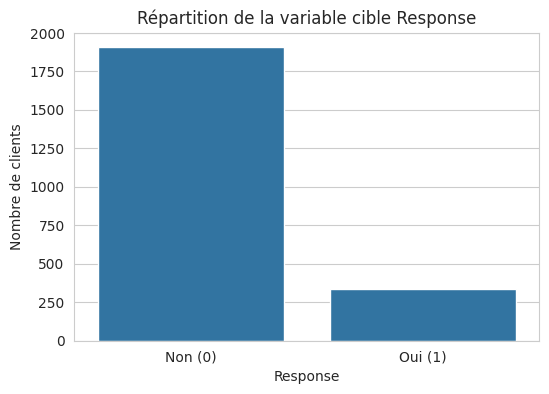

In [6]:
# Déséquilibre de la variable cible
# Comptage absolu et en pourcentage
response_counts = df['Response'].value_counts()
response_pct = df['Response'].value_counts(normalize=True) * 100

print("Répartition de Response :")
print(response_counts)
print("\nPourcentages :")
print(response_pct.round(2))

# Visualisation
plt.figure(figsize=(6, 4))
sns.countplot(x='Response', data=df)
plt.xticks([0, 1], ['Non (0)', 'Oui (1)'])
plt.title('Répartition de la variable cible Response')
plt.ylabel('Nombre de clients')
plt.show()

**Interprétation**

- **1 906 clients n'ont pas répondu (85,1 %)** et **334 ont répondu (14,9 %)** : un déséquilibre modéré, mais bien réel.
- Un modèle qui répondrait toujours « pas de réponse » obtiendrait environ **85 % d'accuracy** sans repérer aucun répondeur : l'**accuracy est donc trompeuse** ici.
- Conséquences pour la suite : découpage train / test **stratifié** (même proportion de répondeurs dans chaque partie), **validation croisée stratifiée** pour comparer les modèles, et métriques centrées sur la classe « réponse » : **precision, recall, F1 et PR-AUC**. Un modèle sans aucune information obtient un PR-AUC égal à la proportion de répondeurs, soit **≈ 0,15** : c'est la référence à battre.

### 2.3 Le revenu (`Income`) : distribution, valeurs manquantes, valeurs extrêmes

`Income` est probablement une variable importante, mais elle pose deux questions : que faire des 24 valeurs manquantes, et que penser des valeurs très élevées ?

count      2216.00
mean      52247.25
std       25173.08
min        1730.00
25%       35303.00
50%       51381.50
75%       68522.00
max      666666.00
Name: Income, dtype: float64


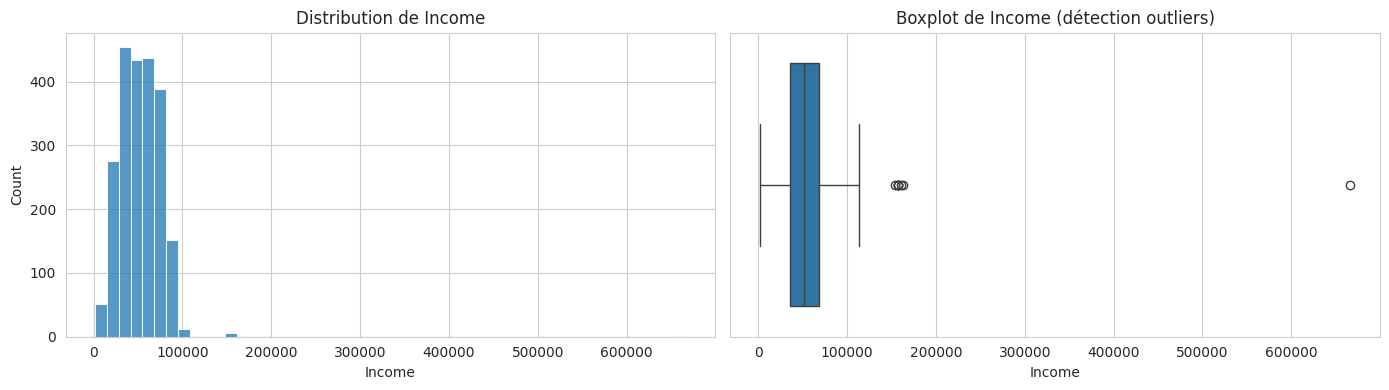


Response pour les lignes avec Income manquant :
Response
0    23
1     1
Name: count, dtype: int64


In [7]:
# Distribution de Income et valeurs manquantes
print(df['Income'].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['Income'].dropna(), bins=50, ax=axes[0])
axes[0].set_title('Distribution de Income')

sns.boxplot(x=df['Income'], ax=axes[1])
axes[1].set_title('Boxplot de Income (détection outliers)')

plt.tight_layout()
plt.show()

# Les 24 valeurs manquantes posent-elles problème sur Response ?
print("\nResponse pour les lignes avec Income manquant :")
print(df[df['Income'].isnull()]['Response'].value_counts())

**Interprétation**

- **24 revenus manquants** (1,1 %) : 23 de ces clients n'ont pas répondu et 1 a répondu (4 % de réponses, contre 14,9 % en moyenne). Avec 24 lignes, c'est trop peu pour y voir un signal : l'absence de revenu ne semble pas liée à la réponse. On imputera ces valeurs par la **médiane** (robuste aux valeurs extrêmes), calculée **uniquement sur les données d'entraînement** à l'intérieur du pipeline, pour éviter toute fuite de données.
- **Une valeur extrême** : le maximum est de 666 666, alors que la médiane est de 51 381 et le 75e percentile de 68 522.

#### Les valeurs les plus élevées de `Income`

On regarde combien de clients ont des revenus très élevés, et si le reste de leur profil est cohérent.

In [8]:
# Les valeurs les plus élevées de Income
print(df['Income'].sort_values(ascending=False).head(10))

# Combien de lignes au-dessus de seuils plausibles ?
for seuil in [150000, 200000]:
    print(f"Income > {seuil} :", (df['Income'] > seuil).sum(), "lignes")

# Que valent ces clients sur les autres variables ?
df[df['Income'] > 150000][['ID', 'Year_Birth', 'Income', 'MntWines', 'NumWebPurchases', 'Response']]

2233    666666.0
617     162397.0
687     160803.0
1300    157733.0
164     157243.0
1653    157146.0
2132    156924.0
655     153924.0
1898    113734.0
646     105471.0
Name: Income, dtype: float64
Income > 150000 : 8 lignes
Income > 200000 : 1 lignes


,ID,Year_Birth,Income,MntWines,NumWebPurchases,Response
164,8475,1973,157243.0,20,0,0
617,1503,1976,162397.0,85,0,0
655,5555,1975,153924.0,1,0,0
687,1501,1982,160803.0,55,0,0
1300,5336,1971,157733.0,39,1,0
1653,4931,1977,157146.0,1,0,0
2132,11181,1949,156924.0,2,0,0
2233,9432,1977,666666.0,9,3,0


- La valeur **666 666 est isolée** : le deuxième revenu le plus élevé est 162 397.
- Sept autres clients ont des revenus entre 153 924 et 162 397, puis la valeur suivante tombe à 113 734 : un petit groupe à part, qui peut être réel ou non. On compare leur comportement d'achat à la médiane de la base dans la cellule suivante.

In [9]:
# Comportement d'achat des clients à Income > 150 000, comparé à la médiane de la base
high_income = df[df['Income'] > 150000].index

cols = ['MntWines', 'MntMeatProducts', 'NumStorePurchases', 'NumCatalogPurchases', 'NumWebVisitsMonth']

print("Médiane de l'ensemble des clients :")
print(df[cols].median())

print("\nClients à Income > 150k :")
print(df.loc[high_income, cols])

Médiane de l'ensemble des clients :
MntWines               173.5
MntMeatProducts         67.0
NumStorePurchases        5.0
NumCatalogPurchases      2.0
NumWebVisitsMonth        6.0
dtype: float64

Clients à Income > 150k :
      MntWines  MntMeatProducts  NumStorePurchases  NumCatalogPurchases  \
164         20             1582                  0                   22   
617         85               16                  1                    0   
655          1                1                  0                    0   
687         55             1622                  1                   28   
1300        39                9                  1                    0   
1653         1             1725                  0                   28   
2132         2                2                  0                    0   
2233         9               18                  3                    1   

      NumWebVisitsMonth  
164                   0  
617                   1  
655                   0

**Interprétation** : ces 8 clients ne forment pas un seul profil.

- **Trois clients très atypiques mais cohérents** (lignes 164, 687, 1653) : plus de 1 580 dépensés en viande (médiane de la base : 67) et 22 à 28 achats par catalogue (médiane : 2), avec presque aucun achat en magasin. Un comportement extrême, mais plausible pour des acheteurs en gros.
- **Quatre clients quasi inactifs** (lignes 617, 655, 1300, 2132) : dépenses presque nulles et peu de visites web malgré un revenu élevé. Les données ne permettent pas de dire si leur revenu est exact.
- **Le client à 666 666** (ligne 2233) a un profil banal (3 achats en magasin, 6 visites web) qui ne correspond pas à un tel revenu : la valeur est très probablement une **erreur de saisie**.

**Décision** : supprimer la ligne à 666 666, et conserver les 7 autres clients (revenus élevés mais plausibles).

### 2.4 Année de naissance et date d'inscription

On vérifie la plausibilité des âges et on repère la période couverte par les inscriptions, pour pouvoir calculer proprement l'âge et l'ancienneté des clients.

In [10]:
print(df['Year_Birth'].describe())
print("\nLes 10 années de naissance les plus anciennes :")
print(df['Year_Birth'].sort_values().head(10))

# Dt_Customer : conversion en date
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
print("\nPremière inscription :", df['Dt_Customer'].min())
print("Dernière inscription :", df['Dt_Customer'].max())

count    2240.000000
mean     1968.805804
std        11.984069
min      1893.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64

Les 10 années de naissance les plus anciennes :
239     1893
339     1899
192     1900
1950    1940
424     1941
1923    1943
415     1943
894     1943
39      1943
1150    1943
Name: Year_Birth, dtype: int64

Première inscription : 2012-07-30 00:00:00
Dernière inscription : 2014-06-29 00:00:00


**Interprétation**

- **Trois années de naissance impossibles** : 1893, 1899 et 1900 (des clients de plus de 110 ans). La valeur suivante est 1940 : le saut est net, ce sont des erreurs de saisie.
- Le reste de la distribution est cohérent (médiane en 1970, maximum en 1996).
- Les inscriptions s'étalent du **30 juillet 2012 au 29 juin 2014**. Pour calculer l'âge et l'ancienneté, on n'utilisera pas la date du jour (l'âge de tous serait décalé d'une dizaine d'années sans raison) mais une **date de référence fixe : le 1er juillet 2014**, juste après la fin de la collecte.

### 2.5 Suppression des valeurs aberrantes

Deux erreurs de saisie sont identifiées : le revenu de 666 666 et les trois années de naissance impossibles. On **supprime ces 4 lignes** plutôt que de les corriger par une valeur estimée : on ne sait pas ce qui a été mal saisi, et inventer une valeur reviendrait à fabriquer une donnée. L'impact est négligeable (4 lignes sur 2 240, soit 0,18 %).

In [11]:
# Suppression des erreurs de saisie : année de naissance impossible (< 1920) ou revenu de 666 666

print("Shape avant :", df.shape)

mask_aberrant = (df['Income'] == 666666) | (df['Year_Birth'] < 1920)
print("Lignes à supprimer :", mask_aberrant.sum())
print(df.loc[mask_aberrant, ['ID', 'Year_Birth', 'Income', 'Response']])

df = df[~mask_aberrant].reset_index(drop=True)

print("\nShape après :", df.shape)
print("Répartition de Response :")
print(df['Response'].value_counts(normalize=True).round(4) * 100)

Shape avant : (2240, 29)
Lignes à supprimer : 4
         ID  Year_Birth    Income  Response
192    7829        1900   36640.0         0
239   11004        1893   60182.0         0
339    1150        1899   83532.0         0
2233   9432        1977  666666.0         0

Shape après : (2236, 29)
Répartition de Response :
Response
0    85.06
1    14.94
Name: proportion, dtype: float64


Les 4 lignes sont supprimées : il reste **2 236 clients**, et le taux de réponse est quasi inchangé (14,94 % contre 14,91 %). Les analyses qui suivent portent sur ces données nettoyées.

### 2.6 Montants dépensés et canaux d'achat

On étudie les variables de comportement d'achat : les montants dépensés par catégorie de produit (`Mnt...`) et le nombre d'achats par canal (`Num...`). On cherche les distributions très asymétriques et les valeurs aberrantes.

=== Montants dépensés ===
       MntWines  MntFruits  MntMeatProducts  MntFishProducts  \
count    2236.0     2236.0           2236.0           2236.0   
mean      304.1       26.3            167.0             37.5   
std       336.6       39.7            225.7             54.6   
min         0.0        0.0              0.0              0.0   
25%        24.0        1.0             16.0              3.0   
50%       174.0        8.0             67.0             12.0   
75%       504.2       33.0            232.0             50.0   
max      1493.0      199.0           1725.0            259.0   

       MntSweetProducts  MntGoldProds  
count            2236.0        2236.0  
mean               27.1          44.0  
std                41.3          52.1  
min                 0.0           0.0  
25%                 1.0           9.0  
50%                 8.0          24.0  
75%                33.0          56.0  
max               263.0         362.0  

=== Nombre d'achats par canal ===
  

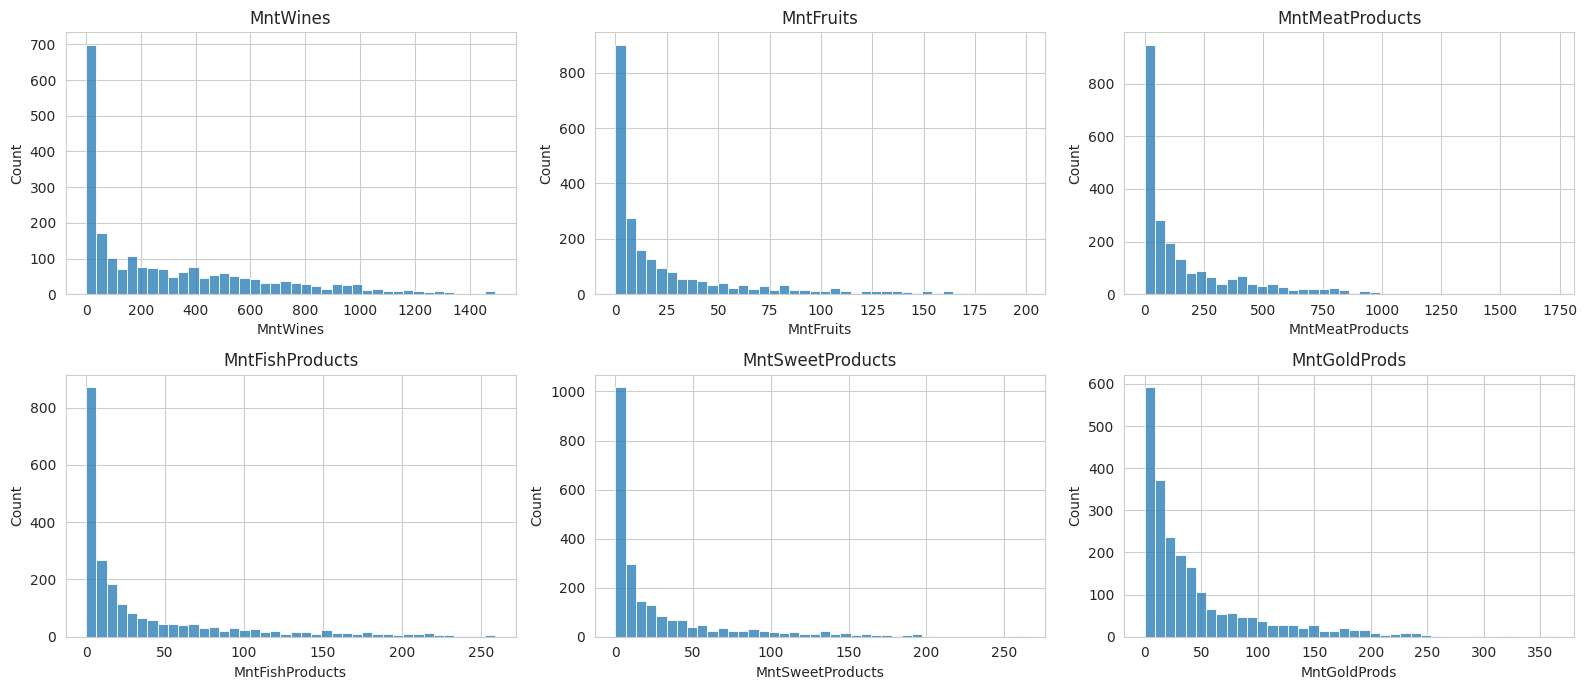

In [12]:
# Montants dépensés (Mnt...) et nombre d'achats par canal (Num...)
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
            'MntSweetProducts', 'MntGoldProds']
num_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
            'NumStorePurchases', 'NumWebVisitsMonth']

print("=== Montants dépensés ===")
print(df[mnt_cols].describe().round(1))

print("\n=== Nombre d'achats par canal ===")
print(df[num_cols].describe().round(1))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flatten(), mnt_cols):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interprétation**

- **Toutes les distributions de montants sont très asymétriques à droite** : beaucoup de clients dépensent peu ou rien dans une catégorie, quelques-uns beaucoup. La moyenne est nettement au-dessus de la médiane (vin : 304 contre 174, viande : 167 contre 67, fruits : 26 contre 8).
- Le **vin** domine les dépenses.
- Les **valeurs maximales ne sont pas des erreurs** : les 1 725 dépensés en viande correspondent aux gros acheteurs par catalogue identifiés plus haut. On les conserve.
- Les magasins sont le canal d'achat principal (médiane de 5 achats), devant le web (4) et le catalogue (2).
- **Conséquence** : les modèles linéaires (régression logistique, SVM) supportent mal ces distributions asymétriques. On appliquera une **transformation logarithmique** (`log1p`) en modélisation ; les modèles à base d'arbres n'en ont pas besoin.

#### Clients sans aucun achat enregistré

On compte les clients dont les compteurs d'achats web, catalogue et magasin sont tous à zéro.

In [13]:
# Clients sans aucun achat web / catalogue / magasin
total_achats = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)
print("Clients sans aucun achat web/catalogue/magasin :", (total_achats == 0).sum())

Clients sans aucun achat web/catalogue/magasin : 6


**6 clients** sont dans ce cas (0,3 % de la base). On vérifie à l'étape suivante (2.8) qu'ils ont tout de même des dépenses enregistrées : si c'est le cas, ce sont de vrais clients et on les conserve.

### 2.7 Taux de réponse selon les variables catégorielles et binaires

Pour chaque variable, on calcule le **taux de réponse par modalité**, avec l'effectif à côté : un taux calculé sur 3 clients ne veut rien dire, et on doit pouvoir le voir tout de suite.

In [14]:
# Taux de réponse par modalité des variables catégorielles et binaires
cat_cols = ['Education', 'Marital_Status', 'Kidhome', 'Teenhome', 'Complain',
            'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']

for col in cat_cols:
    taux = df.groupby(col)['Response'].agg(['mean', 'count'])
    taux['mean'] = (taux['mean'] * 100).round(1)
    taux.columns = ['Taux de réponse (%)', 'Effectif']
    print(f"\n--- {col} ---")
    print(taux)


--- Education ---
            Taux de réponse (%)  Effectif
Education                                
2n Cycle                   10.9       201
Basic                       3.7        54
Graduation                 13.5      1126
Master                     15.4       370
PhD                        20.8       485

--- Marital_Status ---
                Taux de réponse (%)  Effectif
Marital_Status                               
Absurd                         50.0         2
Alone                          33.3         3
Divorced                       20.8       231
Married                        11.3       864
Single                         22.1       479
Together                       10.4       578
Widow                          24.7        77
YOLO                           50.0         2

--- Kidhome ---
         Taux de réponse (%)  Effectif
Kidhome                               
0                       17.2      1291
1                       12.3       897
2                        4.2  

**Interprétation**

**Les campagnes passées sont le signal le plus fort du dataset.**

| Variable | Taux de réponse si accepté | Taux si non accepté |
|---|---|---|
| `AcceptedCmp1` | 54,9 % | 12,2 % |
| `AcceptedCmp2` | 66,7 % (seulement 30 clients) | 14,2 % |
| `AcceptedCmp3` | 47,2 % | 12,4 % |
| `AcceptedCmp4` | 37,1 % | 13,1 % |
| `AcceptedCmp5` | 56,8 % | 11,7 % |

Un client qui a déjà accepté une campagne répond 3 à 5 fois plus. Ce n'est pas une fuite de données : cette information existe avant la dernière campagne.

- **`Education`** : le taux de réponse augmente globalement avec le niveau d'études, de 3,7 % (`Basic`) à 20,8 % (`PhD`). `2n Cycle` (10,9 %, 201 clients) fait exception.
- **`Marital_Status`** : vivre en couple (`Married` 11,3 %, `Together` 10,4 %) va avec deux fois moins de réponses que vivre seul (`Single` 22,1 %, `Divorced` 20,8 %, `Widow` 24,7 %). La vraie frontière est « en couple ou non ». Les taux de `Absurd`, `YOLO` et `Alone` reposent sur 2 à 3 clients : du bruit.
- **Enfants au foyer** : plus il y en a, moins les clients répondent (`Kidhome` : 17,2 % → 12,3 % → 4,2 % ; `Teenhome` : 20,5 % → 8,9 %).
- **`Complain`** : aucun signal (14,9 % contre 15,0 %, sur 20 plaintes seulement).

### 2.8 Variables numériques selon la réponse

On compare les clients répondeurs et non-répondeurs sur le revenu, l'âge, l'ancienneté, la récence et les dépenses. Pour cela, on crée **temporairement** l'âge (`Age`), l'ancienneté (`Customer_Seniority`, en jours jusqu'au 1er juillet 2014) et la dépense totale (`MntTotal`). Cette cellule vérifie aussi le point resté en suspens : les 6 clients sans achat.

Dépenses totales des 6 clients sans achat :
[6 6 8 5 9 8]

Médiane par groupe de réponse :
Response                  0        1
Income              50150.0  64090.0
Age                    44.0     43.0
Customer_Seniority    333.0    492.5
Recency                52.0     30.0
MntTotal              315.0   1057.5
MntWines              152.5    448.0
NumWebVisitsMonth       6.0      6.0
NumDealsPurchases       2.0      1.0


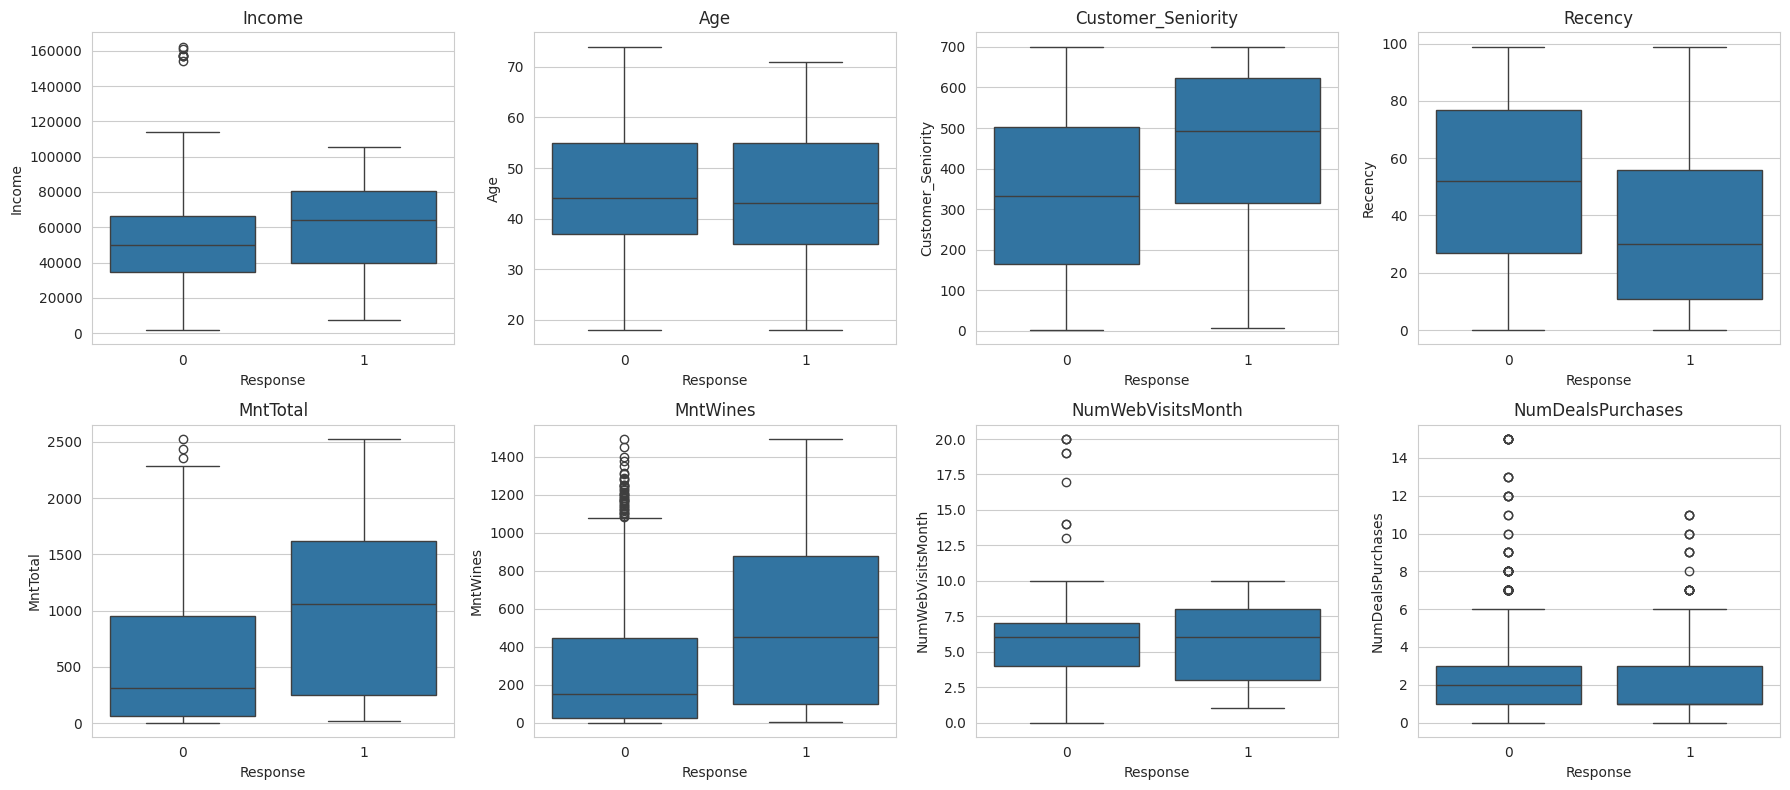

In [15]:
# Vérification des 6 clients sans achat
total_achats = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)
mnt_total = df[['MntWines','MntFruits','MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds']].sum(axis=1)
print("Dépenses totales des 6 clients sans achat :")
print(mnt_total[total_achats == 0].values)

# Variables temporaires pour l'EDA
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])
ref_date = pd.Timestamp('2014-07-01')
df['Age'] = 2014 - df['Year_Birth']
df['Customer_Seniority'] = (ref_date - df['Dt_Customer']).dt.days
df['MntTotal'] = mnt_total

num_vars = ['Income', 'Age', 'Customer_Seniority', 'Recency', 'MntTotal',
            'MntWines', 'NumWebVisitsMonth', 'NumDealsPurchases']

print("\nMédiane par groupe de réponse :")
print(df.groupby('Response')[num_vars].median().round(1).T)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), num_vars):
    sns.boxplot(x='Response', y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interprétation**

Les 6 clients sans achat ont tout de même dépensé entre 5 et 9 : ce sont de vrais clients, on les conserve.

| Variable (médiane) | Non-répondeurs | Répondeurs |
|---|---|---|
| `MntTotal` | 315 | 1 057,5 |
| `MntWines` | 152,5 | 448 |
| `Customer_Seniority` (jours) | 333 | 492,5 |
| `Income` | 50 150 | 64 090 |
| `Recency` (jours) | 52 | 30 |
| `NumDealsPurchases` | 2 | 1 |
| `Age` | 44 | 43 |
| `NumWebVisitsMonth` | 6 | 6 |

**Profil type du répondeur** : un client qui dépense beaucoup (surtout en vin), plus aisé, inscrit depuis plus longtemps et ayant acheté récemment. L'âge et les visites web ne distinguent pas les deux groupes.

**Nuance** : les distributions se chevauchent beaucoup sur les boxplots. Aucune variable ne sépare les deux groupes à elle seule : il faudra combiner plusieurs signaux.

### 2.9 Corrélations

On mesure les corrélations de **Spearman** (adaptées aux distributions asymétriques) : d'une part avec la cible `Response`, d'autre part entre les variables explicatives, pour détecter les redondances.

Corrélation (Spearman) avec Response :
AcceptedCmp5           0.328
AcceptedCmp1           0.294
AcceptedCmp3           0.254
NumCatalogPurchases    0.233
MntMeatProducts        0.223
MntWines               0.199
Recency               -0.198
Customer_Seniority     0.194
MntGoldProds           0.183
AcceptedCmp4           0.177
NumWebPurchases        0.172
AcceptedCmp2           0.169
Income                 0.162
Teenhome              -0.160
MntFruits              0.149
MntSweetProducts       0.136
MntFishProducts        0.116
Kidhome               -0.077
NumStorePurchases      0.053
NumDealsPurchases     -0.036
Age                   -0.020
NumWebVisitsMonth      0.010
Complain               0.000
Name: Response, dtype: float64


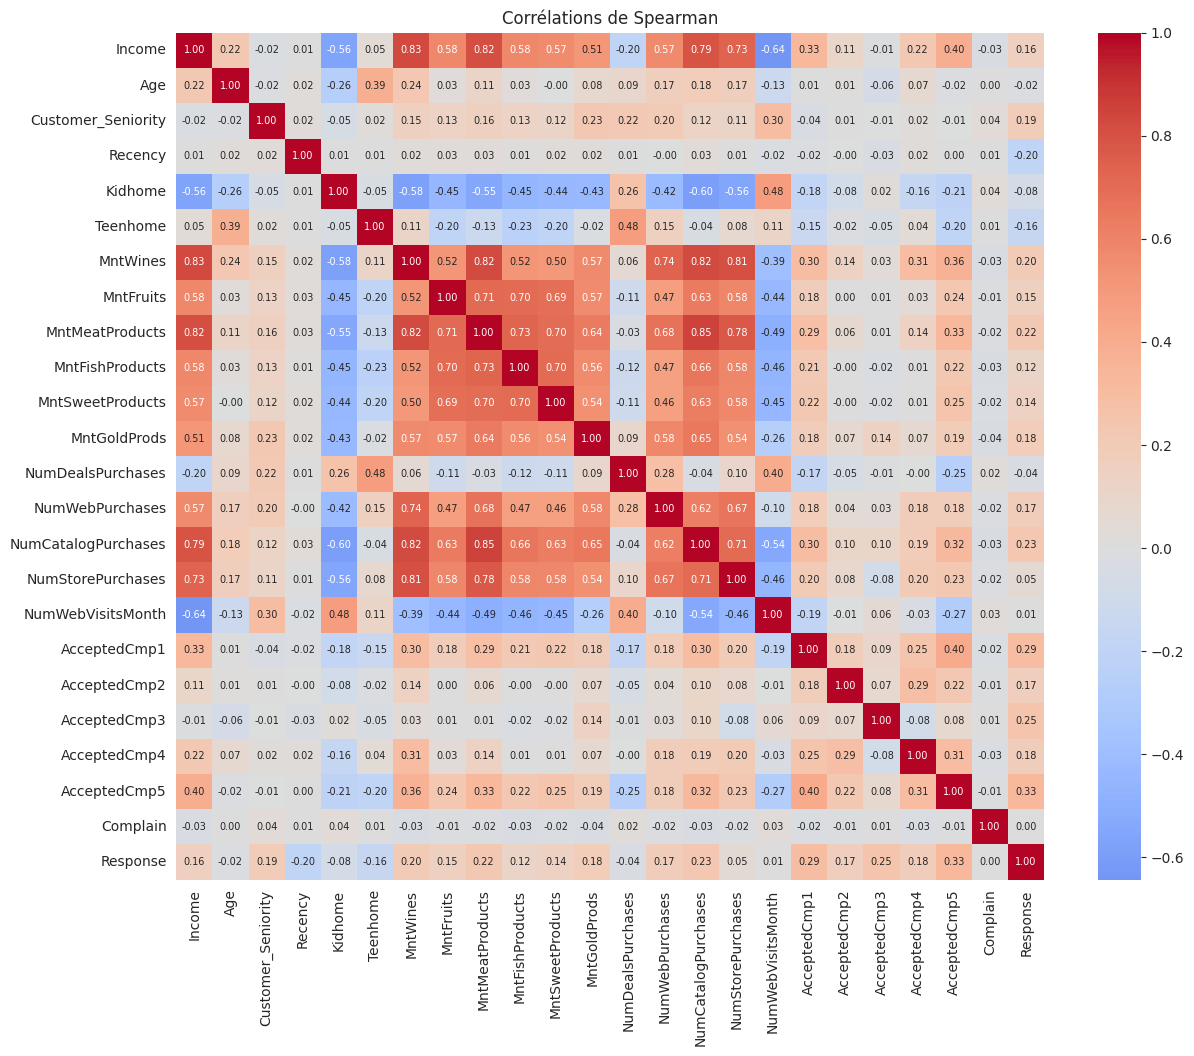

In [16]:
# Corrélations de Spearman : avec la cible Response et entre variables

cols_corr = ['Income', 'Age', 'Customer_Seniority', 'Recency', 'Kidhome', 'Teenhome',
             'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
             'MntSweetProducts', 'MntGoldProds',
             'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
             'NumStorePurchases', 'NumWebVisitsMonth',
             'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5',
             'Complain', 'Response']

corr = df[cols_corr].corr(method='spearman')

print("Corrélation (Spearman) avec Response :")
print(corr['Response'].drop('Response').sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Corrélations de Spearman')
plt.show()

**Interprétation**

**Corrélations avec `Response`** (modérées : le maximum est de 0,33)
- En tête : les campagnes passées (`AcceptedCmp5` 0,33, `AcceptedCmp1` 0,29, `AcceptedCmp3` 0,25), puis `NumCatalogPurchases` (0,23), `MntMeatProducts` (0,22), `MntWines` (0,20), `Recency` (-0,20) et `Customer_Seniority` (0,19).
- Sans lien visible : `Complain` (0,00), `NumWebVisitsMonth` (0,01), `Age` (-0,02), `NumDealsPurchases` (-0,04), `NumStorePurchases` (0,05).
- Une corrélation proche de zéro ne veut pas dire qu'une variable est inutile : elle ne capte que les relations monotones.

**Redondances entre variables explicatives (heatmap)**
- Un **gros bloc de variables très corrélées** : le revenu, les dépenses (vin, viande...) et les achats en catalogue et en magasin, avec des corrélations d'environ 0,7 à 0,8. Les clients aisés dépensent partout. Les modèles linéaires y seront sensibles : leurs coefficients individuels seront peu fiables (cf. étape 5).
- `Recency` et `Customer_Seniority` sont à l'inverse presque indépendantes des autres variables : elles apportent une information distincte.

### 2.10 Synthèse de l'exploration

- Dataset de 2 240 clients, 24 revenus manquants, aucun doublon. `Z_CostContact` et `Z_Revenue` sont constantes, `ID` n'a pas de valeur prédictive.
- Erreurs de saisie traitées : 4 lignes supprimées (revenu de 666 666, années de naissance impossibles) ; `Marital_Status` à nettoyer (étape 3.1).
- Cible déséquilibrée (14,9 % de réponses) : on évaluera avec le PR-AUC, la precision et le recall, par validation croisée stratifiée.
- **Le meilleur signal est l'historique** : un client ayant accepté une campagne passée répond 3 à 5 fois plus.
- Profil du répondeur : dépenses élevées, plus aisé, client ancien, achat récent, peu d'achats en promotion, vivant sans conjoint ni adolescents, plutôt diplômé.
- Sans lien visible avec la réponse : `Complain`, `NumWebVisitsMonth`, `Age`.
- Forte redondance entre revenu, dépenses et canaux d'achat ; montants très asymétriques → transformation logarithmique pour les modèles linéaires.
- Corrélations modérées : il faudra combiner plusieurs variables.

## 3. Préparation des données

On prépare le jeu de données pour la modélisation, en respectant une règle d'or : **aucune information du jeu de test ne doit influencer l'entraînement** (imputation, normalisation, etc.). Les transformations « fixes » (supprimer une colonne, calculer un âge) peuvent se faire avant le découpage ; celles qui apprennent une statistique à partir des données (médiane, moyenne) sont placées dans des pipelines, après le découpage.

### 3.1 Nettoyage de `Marital_Status`

On fusionne `Alone` avec `Single` (même sens : une personne vivant seule) et on supprime les 4 lignes `Absurd` et `YOLO`, dont on ne peut pas déduire la vraie situation.

In [17]:
# Nettoyage de Marital_Status : 'Alone' fusionné avec 'Single', lignes 'Absurd' et 'YOLO' supprimées

print("Shape avant :", df.shape)

# Alone -> Single
df['Marital_Status'] = df['Marital_Status'].replace('Alone', 'Single')

# Suppression des lignes Absurd / YOLO
df = df[~df['Marital_Status'].isin(['Absurd', 'YOLO'])].reset_index(drop=True)

print("Shape après :", df.shape)
print("\n", df['Marital_Status'].value_counts())
print("\nTaux de réponse :", (df['Response'].mean() * 100).round(2), "%")

Shape avant : (2236, 32)
Shape après : (2232, 32)

 Marital_Status
Married     864
Together    578
Single      482
Divorced    231
Widow        77
Name: count, dtype: int64

Taux de réponse : 14.87 %


Il reste **2 232 clients** et 5 modalités cohérentes (`Married` 864, `Together` 578, `Single` 482, `Divorced` 231, `Widow` 77). Le taux de réponse est de 14,87 %.

### 3.2 Création de variables, encodage et suppression des colonnes inutiles

| Transformation | Détail |
|---|---|
| Colonnes supprimées | `ID` (identifiant), `Z_CostContact` et `Z_Revenue` (constantes) |
| `Age` | 2014 − `Year_Birth` (collecte terminée mi-2014) |
| `Customer_Seniority` | nombre de jours entre `Dt_Customer` et le 1er juillet 2014 |
| `Total_Children` | `Kidhome` + `Teenhome` |
| `MntTotal` | somme des six montants dépensés |
| `Total_AcceptedCmp` | nombre de campagnes passées acceptées (0 à 5) |
| `Living_With_Partner` | 1 si `Marital_Status` vaut `Married` ou `Together`, 0 sinon (la vraie frontière observée est « en couple ou non ») |
| `Education_Level` | encodage **ordinal** : `Basic` 0, `Graduation` 1, `2n Cycle` et `Master` 2, `PhD` 3 |

L'ordre des niveaux d'études suit la logique des diplômes (`2n Cycle` correspond à un deuxième cycle universitaire, donc au niveau de `Master`), et non les taux de réponse observés : on évite ainsi d'injecter la cible dans une variable explicative. Les colonnes sources (`Year_Birth`, `Dt_Customer`, `Marital_Status`, `Education`) sont ensuite supprimées.

In [18]:
# Suppression colonnes inutiles et création des variables
# 1. Colonnes sans valeur prédictive
df = df.drop(columns=['ID', 'Z_CostContact', 'Z_Revenue'])

# 2. Nouvelles variables (date de référence fixe, cf. EDA)
ref_date = pd.Timestamp('2014-07-01')
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])

df['Age'] = 2014 - df['Year_Birth']
df['Customer_Seniority'] = (ref_date - df['Dt_Customer']).dt.days
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
mnt_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
            'MntSweetProducts', 'MntGoldProds']
df['MntTotal'] = df[mnt_cols].sum(axis=1)
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df['Total_AcceptedCmp'] = df[cmp_cols].sum(axis=1)
df['Living_With_Partner'] = df['Marital_Status'].isin(['Married', 'Together']).astype(int)

# 3. Encodage ordinal de Education
education_order = {'Basic': 0, 'Graduation': 1, '2n Cycle': 2, 'Master': 2, 'PhD': 3}
df['Education_Level'] = df['Education'].map(education_order)

# 4. Suppression des colonnes sources devenues redondantes
df = df.drop(columns=['Year_Birth', 'Dt_Customer', 'Marital_Status', 'Education'])

print("Shape :", df.shape)
print("\nValeurs manquantes :")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nTypes :")
print(df.dtypes.value_counts())
df.head()

Shape : (2232, 29)

Valeurs manquantes :
Income    24
dtype: int64

Types :
int64      28
float64     1
Name: count, dtype: int64


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Customer_Seniority,MntTotal,Total_Children,Total_AcceptedCmp,Living_With_Partner,Education_Level
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,57,665,1617,0,0,0,1
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,60,115,27,2,0,0,1
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,49,314,776,0,0,1,1
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0,30,141,53,1,0,1,1
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0,33,163,422,1,0,1,3


Le jeu de données comporte **29 colonnes** (28 variables explicatives et la cible), toutes numériques. Seul `Income` contient encore des valeurs manquantes (24) : elles seront imputées dans le pipeline de modélisation.

### 3.3 Séparation en jeu d'entraînement et jeu de test

- **80 % / 20 %**, avec `stratify=y` pour conserver la même proportion de répondeurs dans les deux parties.
- Le **jeu de test est mis de côté** : il ne servira qu'**une seule fois**, à la fin, pour évaluer le modèle retenu. Tous les choix (modèle, réglages) sont faits par validation croisée sur le jeu d'entraînement.

In [19]:
# Split train /test stratifié
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Response'])
y = df['Response']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, "| réponses positives :", y_train.sum())
print("Test  :", X_test.shape, "| réponses positives :", y_test.sum())
print("\nTaux de réponse train :", (y_train.mean() * 100).round(2), "%")
print("Taux de réponse test  :", (y_test.mean() * 100).round(2), "%")

Train : (1785, 28) | réponses positives : 266
Test  : (447, 28) | réponses positives : 66

Taux de réponse train : 14.9 %
Taux de réponse test  : 14.77 %


**Interprétation** : 1 785 clients pour l'entraînement (266 répondeurs) et 447 pour le test (66 répondeurs), avec des taux de réponse quasi identiques (14,90 % et 14,77 %) : la stratification a bien fonctionné.

**Limite à garder en tête** : avec seulement 66 répondeurs dans le test, les scores y sont sensibles à quelques clients (un client en plus ou en moins bien classé déplace le recall d'environ 1,5 point). Les écarts de quelques points entre deux modèles ne seraient donc pas interprétables sur le test seul.

## 4. Modélisation

### 4.1 Protocole de comparaison

Pour comparer les modèles équitablement :
- **Validation croisée stratifiée à 5 plis** sur le jeu d'entraînement : on entraîne sur 4 parties et on évalue sur la 5e, 5 fois, puis on moyenne. Les mêmes plis sont utilisés pour tous les modèles. L'écart-type entre plis (le ± dans les résultats) indique la stabilité du score.
- **Pipelines scikit-learn** : l'imputation et la normalisation sont recalculées à l'intérieur de chaque pli, sans fuite de données.
- **Gestion du déséquilibre** par pondération des classes (`class_weight='balanced'`, ou `scale_pos_weight` pour XGBoost), sans modifier les données.

**Métriques**
- **Recall** : parmi les clients qui répondent vraiment, quelle part le modèle repère-t-il ?
- **Precision** : parmi les clients que le modèle signale, quelle part répond vraiment ?
- **PR-AUC** : aire sous la courbe Precision-Recall, qui résume la qualité du classement des clients quel que soit le seuil de décision. C'est notre **métrique de référence**. Elle se lit par rapport à la proportion de répondeurs (0,15) : un modèle sans information obtient environ 0,15.

### 4.2 Baseline : référence naïve et régression logistique

On commence par un modèle qui ne prédit rien d'utile (la référence à battre), puis par le modèle le plus simple.

In [20]:
# Baseline : référence naïve et régression logistique (validation croisée sur le jeu d'entraînement)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def afficher_cv(nom, resultats, metriques):
    print(f"=== {nom} ===")
    for m in metriques:
        scores = resultats[f'test_{m}']
        print(f"{m:10s}: {scores.mean():.3f} (± {scores.std():.3f})")
    print()

# 1. Référence naïve : prédit toujours la même probabilité (la proportion de réponses)
dummy = DummyClassifier(strategy='prior')
res_dummy = cross_validate(dummy, X_train, y_train, cv=cv,
                           scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'})
afficher_cv("Référence naïve", res_dummy, ['pr_auc', 'roc_auc'])

# 2. Régression logistique (imputation + scaling dans le pipeline)
log_reg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

scoring = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
res_lr = cross_validate(log_reg, X_train, y_train, cv=cv, scoring=scoring)
afficher_cv("Régression logistique (class_weight='balanced')", res_lr,
            ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1'])

=== Référence naïve ===
pr_auc    : 0.149 (± 0.001)
roc_auc   : 0.500 (± 0.000)

=== Régression logistique (class_weight='balanced') ===
pr_auc    : 0.653 (± 0.029)
roc_auc   : 0.903 (± 0.017)
precision : 0.463 (± 0.014)
recall    : 0.808 (± 0.082)
f1        : 0.586 (± 0.018)



**Interprétation**

- **Référence naïve** : PR-AUC de 0,149 (la proportion de répondeurs) et ROC-AUC de 0,500. C'est le plancher.
- **Régression logistique** : PR-AUC de **0,653** (± 0,029), soit environ 4,4 fois le plancher. Au seuil de 0,5 : recall de 0,81 et precision de 0,46.
- Le recall varie davantage d'un pli à l'autre (± 0,082) que le PR-AUC : chaque pli ne contient qu'une cinquantaine de répondeurs. C'est pourquoi on compare les modèles sur le PR-AUC, qui ne dépend pas du seuil.

### 4.3 Modèles à base d'arbres : Random Forest et XGBoost

L'exploration suggérait qu'un modèle non linéaire pourrait faire mieux (corrélations linéaires modérées). On le teste avec les mêmes plis. XGBoost accepte les valeurs manquantes et n'a pas besoin d'imputation ; `scale_pos_weight` (rapport négatifs / positifs, ≈ 5,7) joue le rôle de `class_weight`.

In [21]:
# Random Forest et XGBoost (mêmes plis de validation croisée)

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Random Forest
rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                     random_state=42, n_jobs=-1))
])
res_rf = cross_validate(rf, X_train, y_train, cv=cv, scoring=scoring)
afficher_cv("Random Forest (class_weight='balanced')", res_rf,
            ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1'])

# XGBoost (gère nativement les valeurs manquantes, donc pas d'imputation)
# scale_pos_weight = rapport négatifs / positifs, un simple compte des classes
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight :", round(spw, 2))

xgb = XGBClassifier(n_estimators=300, scale_pos_weight=spw, random_state=42,
                    eval_metric='aucpr', n_jobs=-1)
res_xgb = cross_validate(xgb, X_train, y_train, cv=cv, scoring=scoring)
afficher_cv("XGBoost (scale_pos_weight)", res_xgb,
            ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1'])

=== Random Forest (class_weight='balanced') ===
pr_auc    : 0.630 (± 0.027)
roc_auc   : 0.895 (± 0.021)
precision : 0.797 (± 0.098)
recall    : 0.271 (± 0.057)
f1        : 0.398 (± 0.064)

scale_pos_weight : 5.71
=== XGBoost (scale_pos_weight) ===
pr_auc    : 0.649 (± 0.030)
roc_auc   : 0.901 (± 0.026)
precision : 0.667 (± 0.060)
recall    : 0.545 (± 0.074)
f1        : 0.593 (± 0.021)



**Interprétation**

| Modèle | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|
| Régression logistique | 0,653 (± 0,029) | 0,463 | 0,808 | 0,586 |
| Random Forest | 0,630 (± 0,027) | 0,797 | 0,271 | 0,398 |
| XGBoost | 0,649 (± 0,030) | 0,667 | 0,545 | 0,593 |

- Les trois modèles sont **à égalité sur le PR-AUC** : l'écart maximal (0,023) est de l'ordre de la variation entre plis (≈ 0,03). Aucun n'est démontré meilleur.
- **L'hypothèse de départ n'est pas confirmée** : un modèle non linéaire ne fait pas mieux ici. Explications plausibles : les signaux principaux sont monotones (plus un client a accepté de campagnes, dépensé et acheté récemment, plus il répond), et le dataset est petit, ce qui favorise le surapprentissage des arbres.
- Les écarts de precision et de recall viennent surtout du **seuil de 0,5** : Random Forest est très prudent (peu d'alertes, mais fiables), la régression logistique est plus large. Ce sont des points de fonctionnement différents, pas des niveaux de qualité différents : d'où l'usage du PR-AUC.

### 4.4 Courbes Precision-Recall

On visualise le compromis precision / recall des trois modèles à partir des prédictions de validation croisée (chaque client est prédit par un modèle qui ne l'a pas vu à l'entraînement).

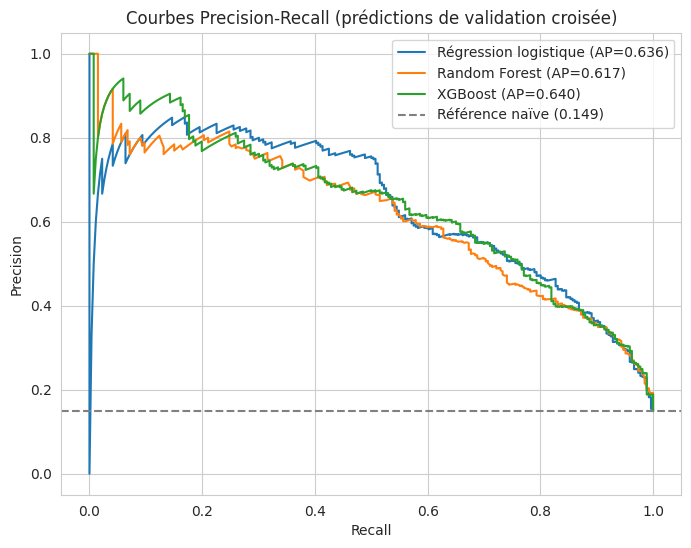


Régression logistique
  recall >= 0.6 : seuil = 0.733, precision = 0.586
  recall >= 0.7 : seuil = 0.650, precision = 0.550
  recall >= 0.8 : seuil = 0.512, precision = 0.472

Random Forest
  recall >= 0.6 : seuil = 0.293, precision = 0.588
  recall >= 0.7 : seuil = 0.237, precision = 0.511
  recall >= 0.8 : seuil = 0.173, precision = 0.423

XGBoost
  recall >= 0.6 : seuil = 0.335, precision = 0.611
  recall >= 0.7 : seuil = 0.109, precision = 0.548
  recall >= 0.8 : seuil = 0.021, precision = 0.454


In [22]:
# Courbes Precision-Recall (prédictions de validation croisée) et precision atteignable pour un recall donné
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

modeles = {'Régression logistique': log_reg, 'Random Forest': rf, 'XGBoost': xgb}
proba_oof = {}
for nom, modele in modeles.items():
    proba_oof[nom] = cross_val_predict(modele, X_train, y_train, cv=cv,
                                       method='predict_proba')[:, 1]

plt.figure(figsize=(8, 6))
for nom, p in proba_oof.items():
    prec, rec, _ = precision_recall_curve(y_train, p)
    plt.plot(rec, prec, label=f"{nom} (AP={average_precision_score(y_train, p):.3f})")
plt.axhline(y_train.mean(), color='grey', linestyle='--',
            label=f'Référence naïve ({y_train.mean():.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Courbes Precision-Recall (prédictions de validation croisée)')
plt.legend()
plt.grid(True)
plt.show()

# Precision atteignable pour différents niveaux de recall
for nom, p in proba_oof.items():
    prec, rec, thr = precision_recall_curve(y_train, p)
    print(f"\n{nom}")
    for cible in [0.6, 0.7, 0.8]:
        idx = np.where(rec[:-1] >= cible)[0][-1]
        print(f"  recall >= {cible} : seuil = {thr[idx]:.3f}, precision = {prec[idx]:.3f}")

**Interprétation**

- Les trois courbes sont **presque superposées** et très au-dessus de la référence naïve (0,149).
- À recall égal, la precision est proche :

| Recall visé | Régression logistique | Random Forest | XGBoost |
|---|---|---|---|
| 0,6 | 0,586 | 0,588 | 0,611 |
| 0,7 | 0,550 | 0,511 | 0,548 |
| 0,8 | 0,472 | 0,423 | 0,454 |

- Les écarts visibles à faible recall (< 0,2) reposent sur une cinquantaine de clients : c'est du bruit plus que de la performance.
- Les seuils ne sont pas comparables d'un modèle à l'autre (XGBoost a besoin d'un seuil de 0,021 pour atteindre 80 % de recall) : on compare les modèles sur le classement qu'ils produisent, pas sur leurs probabilités.

### 4.5 SVM à noyau RBF

On teste une famille différente : la SVM, qui cherche une frontière lisse entre les deux groupes. Comme elle est sensible à l'échelle et aux distributions asymétriques (cf. 2.6), on applique d'abord une **transformation logarithmique** (`log1p`) aux montants et aux compteurs d'achats, puis l'imputation et la normalisation. Une petite grille explore les deux réglages principaux, `C` et `gamma`.

In [25]:
# SVM à noyau RBF, avec transformation log des variables asymétriques
# (log_cols est aussi réutilisée par la régression logistique à l'étape suivante)
from sklearn.svm import SVC
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import GridSearchCV

log_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
            'MntSweetProducts', 'MntGoldProds', 'MntTotal',
            'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases']

def pipeline_svm(C=1.0, gamma='scale'):
    return Pipeline([
        ('log', ColumnTransformer(
            [('log', FunctionTransformer(np.log1p), log_cols)],
            remainder='passthrough')),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=C, gamma=gamma, class_weight='balanced'))
    ])

# 1. SVM avec réglages par défaut
res_svm = cross_validate(pipeline_svm(), X_train, y_train, cv=cv, scoring=scoring)
afficher_cv("SVM RBF (C=1, gamma='scale')", res_svm,
            ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1'])

# 2. Petite grille sur C et gamma
grille_svm = GridSearchCV(
    pipeline_svm(),
    {'model__C': [0.1, 1, 10], 'model__gamma': [0.003, 0.01, 0.03]},
    scoring='average_precision', cv=cv)
grille_svm.fit(X_train, y_train)

print("PR-AUC par combinaison :")
for params, s in zip(grille_svm.cv_results_['params'], grille_svm.cv_results_['mean_test_score']):
    print(f"  C={params['model__C']}, gamma={params['model__gamma']}: {s:.3f}")
print("Meilleure combinaison :", grille_svm.best_params_)

=== SVM RBF (C=1, gamma='scale') ===
pr_auc    : 0.646 (± 0.029)
roc_auc   : 0.914 (± 0.013)
precision : 0.504 (± 0.025)
recall    : 0.789 (± 0.088)
f1        : 0.612 (± 0.018)

PR-AUC par combinaison :
  C=0.1, gamma=0.003: 0.608
  C=0.1, gamma=0.01: 0.638
  C=0.1, gamma=0.03: 0.635
  C=1, gamma=0.003: 0.693
  C=1, gamma=0.01: 0.681
  C=1, gamma=0.03: 0.649
  C=10, gamma=0.003: 0.683
  C=10, gamma=0.01: 0.650
  C=10, gamma=0.03: 0.646
Meilleure combinaison : {'model__C': 1, 'model__gamma': 0.003}


**Interprétation**

- Avec les réglages par défaut : PR-AUC de **0,646** (± 0,029), au niveau des modèles précédents.
- La grille atteint 0,693 (`C=1`, `gamma=0,003`), mais ce score est **optimiste** : c'est le meilleur de 9 combinaisons évaluées sur les mêmes plis.
- La SVM est **sensible à ses réglages** : le PR-AUC va de 0,608 à 0,693 selon la combinaison, ce qui est un défaut de robustesse.
- Le meilleur `gamma` testé est la plus petite valeur de la grille (frontière très lisse, presque linéaire), ce qui suggère que le signal est plutôt simple.
- **Point d'équité** : cette SVM a bénéficié de la transformation logarithmique, pas la régression logistique comparée jusqu'ici. On corrige cela à l'étape suivante.

### 4.6 Régression logistique avec transformation logarithmique

On applique à la régression logistique le **même traitement** que pour la SVM, puis on règle la force de régularisation `C` (plus `C` est petit, plus la régularisation est forte : utile avec des variables très corrélées entre elles).

In [26]:
# Régression logistique avec transformation log, puis réglage de la régularisation C
def pipeline_logreg(C=1.0):
    return Pipeline([
        ('log', ColumnTransformer(
            [('log', FunctionTransformer(np.log1p), log_cols)],
            remainder='passthrough')),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(C=C, class_weight='balanced',
                                     max_iter=2000, random_state=42))
    ])

res_log = cross_validate(pipeline_logreg(), X_train, y_train, cv=cv, scoring=scoring)
afficher_cv("Régression logistique + log1p (C=1)", res_log,
            ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1'])

grille_lr = GridSearchCV(pipeline_logreg(), {'model__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1]},
                         scoring='average_precision', cv=cv)
grille_lr.fit(X_train, y_train)
for c, s in zip(grille_lr.cv_results_['param_model__C'], grille_lr.cv_results_['mean_test_score']):
    print(f"  C = {c}: {s:.3f}")
print("Meilleur C :", grille_lr.best_params_['model__C'])

=== Régression logistique + log1p (C=1) ===
pr_auc    : 0.681 (± 0.029)
roc_auc   : 0.915 (± 0.017)
precision : 0.480 (± 0.031)
recall    : 0.819 (± 0.072)
f1        : 0.604 (± 0.032)

  C = 0.003: 0.656
  C = 0.01: 0.685
  C = 0.03: 0.692
  C = 0.1: 0.687
  C = 0.3: 0.681
  C = 1.0: 0.681
Meilleur C : 0.03


**Interprétation**

- La seule transformation logarithmique fait passer le PR-AUC de 0,653 à **0,681** (± 0,029).
- Le réglage de `C` donne un **plateau** : de 0,681 à 0,692 pour `C` entre 0,01 et 1. Seule la valeur la plus faible (`C=0,003`, trop de régularisation) décroche (0,656). Le meilleur est `C=0,03` (0,692, valeur optimiste car sélectionnée sur les mêmes plis).
- À traitement égal, la régression logistique **rattrape la SVM** (≈ 0,69 pour les deux) : la préparation des variables comptait plus que le choix du modèle.

### 4.7 Bilan de la comparaison et choix du modèle

| Modèle | PR-AUC (validation croisée) |
|---|---|
| Référence naïve | 0,149 |
| Random Forest | 0,630 |
| SVM (réglages par défaut) | 0,646 |
| XGBoost | 0,649 |
| Régression logistique | 0,653 |
| **Régression logistique + log1p** (`C=1`) | **0,681** |
| Régression logistique + log1p (`C=0,03`) | 0,692 (optimiste) |
| SVM réglée (meilleure combinaison) | 0,693 (optimiste) |

Tous les modèles sérieux sont sur le même plateau (≈ 0,65 à 0,69), avec une variation entre plis d'environ 0,03 : un écart de quelques points n'est pas démontré.

**Modèle retenu : régression logistique avec transformation logarithmique, `class_weight='balanced'` et `C = 0,03`.** À performance équivalente, on retient le modèle :
- le **plus simple** ;
- le plus **stable** (plateau sur `C`, contrairement à la SVM) ;
- le plus **interprétable** : ses coefficients indiquent quelles variables font monter ou baisser la probabilité de répondre, ce qui répond à la question « qu'est-ce qui explique la réponse ? » et alimente le dashboard.

## 5. Interprétation du modèle

### 5.1 Coefficients de la régression logistique

On entraîne le modèle retenu sur le jeu d'entraînement et on lit ses coefficients. Les variables étant standardisées, ils sont comparables entre eux. L'**odds ratio** (exponentielle du coefficient) indique de combien sont multipliées les chances de répondre quand la variable augmente d'un écart-type, **les autres variables restant fixes** : 2,12 signifie plus que doubler, 0,47 signifie environ diviser par deux.

                     coefficient  odds_ratio
Recency                   -0.757        0.47
Customer_Seniority         0.750        2.12
NumStorePurchases         -0.642        0.53
MntMeatProducts            0.509        1.66
Living_With_Partner       -0.447        0.64
NumCatalogPurchases        0.438        1.55
Teenhome                  -0.386        0.68
Education_Level            0.371        1.45
Total_AcceptedCmp          0.365        1.44
MntWines                  -0.345        0.71
AcceptedCmp3               0.321        1.38
AcceptedCmp5               0.276        1.32
Kidhome                    0.220        1.25
AcceptedCmp1               0.219        1.25
NumDealsPurchases          0.206        1.23
NumWebPurchases            0.201        1.22
NumWebVisitsMonth          0.200        1.22
MntFruits                  0.137        1.15
Total_Children            -0.119        0.89
AcceptedCmp2               0.112        1.12
MntFishProducts           -0.105        0.90
Age       

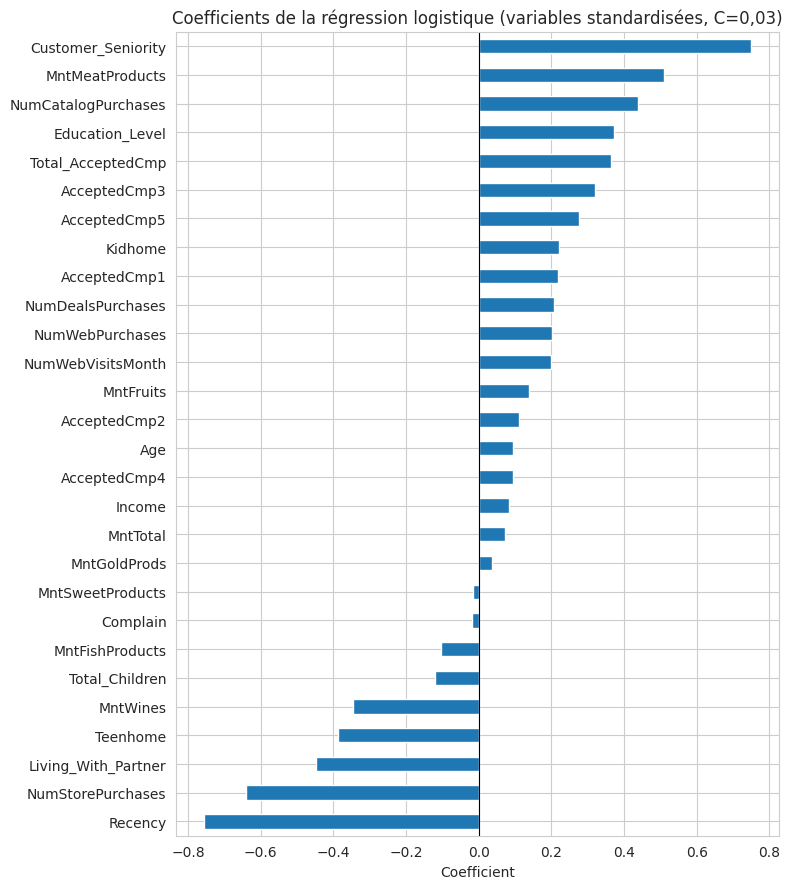

In [27]:
# Coefficients du modèle retenu (régression logistique, C = 0.03) entraîné sur le jeu d'entraînement
final_lr = pipeline_logreg(C=0.03)
final_lr.fit(X_train, y_train)

# Noms des colonnes dans l'ordre du pipeline : d'abord log_cols, puis le reste
noms = log_cols + [c for c in X_train.columns if c not in log_cols]
coefs = pd.Series(final_lr.named_steps['model'].coef_[0], index=noms)

tableau = pd.DataFrame({'coefficient': coefs.round(3),
                        'odds_ratio': np.exp(coefs).round(2)})
tableau = tableau.reindex(coefs.abs().sort_values(ascending=False).index)
print(tableau)

plt.figure(figsize=(8, 9))
coefs.sort_values().plot(kind='barh')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coefficients de la régression logistique (variables standardisées, C=0,03)')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

**Interprétation**

**Coefficients cohérents avec l'exploration**
- `Customer_Seniority` (odds ratio 2,12) : un client plus ancien répond nettement plus.
- `Recency` (0,47) : plus le dernier achat est ancien, moins le client répond.
- `MntMeatProducts` (1,66), `NumCatalogPurchases` (1,55), `Education_Level` (1,45).
- `Living_With_Partner` (0,64) et `Teenhome` (0,68) : vivre en couple ou avoir des adolescents réduit la réponse.
- Les campagnes passées sont toutes positives (`Total_AcceptedCmp` 1,44, `AcceptedCmp3` 1,38, `AcceptedCmp5` 1,32...).

**Trois coefficients qui contredisent l'exploration, et qu'il ne faut pas interpréter tels quels** : `NumStorePurchases` (0,53, négatif alors que sa corrélation avec la réponse était faiblement positive), `MntWines` (0,71, négatif alors que les répondeurs dépensent trois fois plus en vin) et `Kidhome` (1,25, positif alors que le taux de réponse baisse avec le nombre de jeunes enfants). Ces variables sont très liées à d'autres variables du modèle : le coefficient mesure alors l'effet « à autres variables égales », qui peut changer de signe. Dire que « acheter du vin diminue la réponse » serait faux.

**Colinéarité exacte** : `Total_Children` (= `Kidhome` + `Teenhome`) et `Total_AcceptedCmp` (= somme des cinq `AcceptedCmp`) sont des combinaisons de colonnes déjà présentes, ce qui rend la répartition des coefficients entre elles arbitraire. Seul leur sens global est lisible.

**Conclusion** : on ne lit pas les coefficients un par un, mais **par groupes de variables**, ce que fait l'étape suivante.

### 5.2 Importance par groupes de variables

Comme les coefficients individuels sont fragiles (variables redondantes), on mesure l'importance de **groupes** de variables par **permutation** : sur les données de validation, on mélange au hasard les valeurs d'un groupe entier (les colonnes d'un groupe sont mélangées ensemble, ce qui préserve leurs liens internes) et on mesure de combien le PR-AUC baisse. Plus la baisse est grande, plus le groupe compte. Tout se passe en validation croisée sur le jeu d'entraînement ; le test reste intact.

In [28]:
# Importance par groupes de variables : baisse du PR-AUC quand on mélange les valeurs d'un groupe (permutation)
from sklearn.metrics import average_precision_score

groupes = {
    'Campagnes passées': ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
                          'AcceptedCmp4', 'AcceptedCmp5', 'Total_AcceptedCmp'],
    'Dépenses par produit': mnt_cols + ['MntTotal'],
    'Canaux d\'achat': ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
                        'NumStorePurchases', 'NumWebVisitsMonth'],
    'Récence': ['Recency'],
    'Ancienneté': ['Customer_Seniority'],
    'Foyer': ['Kidhome', 'Teenhome', 'Total_Children', 'Living_With_Partner'],
    'Profil (revenu, âge, études)': ['Income', 'Age', 'Education_Level'],
    'Plainte': ['Complain']
}

rng = np.random.RandomState(42)
n_repeats = 10
chutes_par_pli = {g: [] for g in groupes}

for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    modele = pipeline_logreg(C=0.03).fit(X_tr, y_tr)
    ref = average_precision_score(y_val, modele.predict_proba(X_val)[:, 1])

    for g, cols in groupes.items():
        chutes = []
        for _ in range(n_repeats):
            X_perm = X_val.copy()
            ordre = rng.permutation(len(X_perm))
            X_perm[cols] = X_val[cols].values[ordre]
            score = average_precision_score(y_val, modele.predict_proba(X_perm)[:, 1])
            chutes.append(ref - score)
        chutes_par_pli[g].append(np.mean(chutes))

resume = pd.DataFrame({
    'baisse moyenne du PR-AUC': {g: np.mean(v) for g, v in chutes_par_pli.items()},
    'écart-type entre plis': {g: np.std(v) for g, v in chutes_par_pli.items()}
}).sort_values('baisse moyenne du PR-AUC', ascending=False).round(3)
print(resume)

                              baisse moyenne du PR-AUC  écart-type entre plis
Campagnes passées                                0.323                  0.046
Récence                                          0.109                  0.024
Foyer                                            0.093                  0.023
Ancienneté                                       0.087                  0.029
Canaux d'achat                                   0.071                  0.009
Profil (revenu, âge, études)                     0.037                  0.010
Dépenses par produit                             0.025                  0.009
Plainte                                         -0.001                  0.002


**Interprétation** (PR-AUC de départ ≈ 0,69)

| Groupe | Baisse du PR-AUC | Écart-type entre plis |
|---|---|---|
| Campagnes passées | 0,323 | 0,046 |
| Récence | 0,109 | 0,024 |
| Foyer | 0,093 | 0,023 |
| Ancienneté | 0,087 | 0,029 |
| Canaux d'achat | 0,071 | 0,009 |
| Profil (revenu, âge, études) | 0,037 | 0,010 |
| Dépenses par produit | 0,025 | 0,009 |
| Plainte | -0,001 | 0,002 |

- **Les campagnes passées dominent** : en brouillant ce groupe, le PR-AUC chute d'environ 0,32, soit trois fois plus que pour n'importe quel autre groupe. **Le meilleur prédicteur d'une réponse est d'avoir déjà répondu.** Sans cet historique, le modèle reste au-dessus du plancher (≈ 0,37 contre 0,15) : les autres variables portent un vrai signal.
- Viennent ensuite la **récence**, le **foyer** et l'**ancienneté**. L'ordre entre ces trois groupes n'est pas fiable (leurs baisses sont proches de l'écart-type entre plis).
- Les **dépenses** ressortent faiblement, mais cela ne veut pas dire qu'elles sont inutiles : très liées au revenu et aux canaux d'achat, elles sont « compensées » par ces variables quand on les brouille. Cette méthode **sous-estime les groupes redondants entre eux**.
- **`Plainte` n'apporte rien**, comme l'exploration le laissait voir.

## 6. Évaluation finale sur le jeu de test

On utilise le jeu de test **une seule fois**, avec le modèle retenu, sans rien ajuster ensuite. Comme il ne contient que 66 répondeurs, on calcule aussi un **intervalle de confiance du PR-AUC par bootstrap** (1 000 rééchantillonnages des clients du test) pour mesurer l'incertitude.

Référence naïve (proportion de réponses) : 0.148
PR-AUC  : 0.639
ROC-AUC : 0.906

                 precision    recall  f1-score   support

Pas de réponse       0.96      0.85      0.90       381
       Réponse       0.47      0.80      0.60        66

      accuracy                           0.84       447
     macro avg       0.72      0.82      0.75       447
  weighted avg       0.89      0.84      0.85       447

Matrice de confusion :
[[322  59]
 [ 13  53]]

Intervalle de confiance à 95 % du PR-AUC : [0.517 0.764]


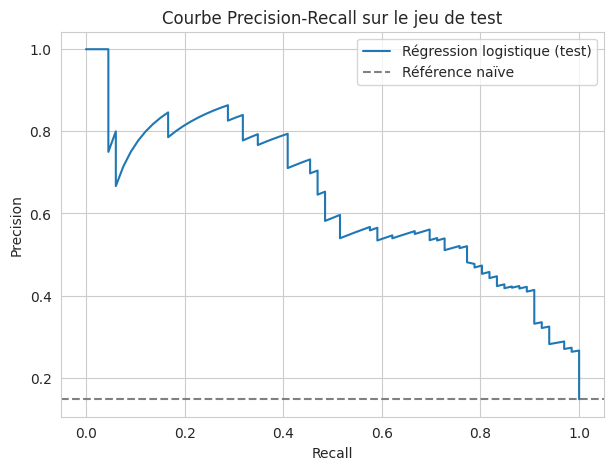

In [29]:
# Évaluation finale sur le jeu de test (utilisé une seule fois)
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_curve, average_precision_score, roc_auc_score)

proba_test = final_lr.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

print("Référence naïve (proportion de réponses) :", round(y_test.mean(), 3))
print("PR-AUC  :", round(average_precision_score(y_test, proba_test), 3))
print("ROC-AUC :", round(roc_auc_score(y_test, proba_test), 3))
print("\n", classification_report(y_test, pred_test,
                                  target_names=['Pas de réponse', 'Réponse']))
print("Matrice de confusion :")
print(confusion_matrix(y_test, pred_test))

# Intervalle de confiance du PR-AUC par bootstrap
rng = np.random.RandomState(42)
y_arr = y_test.values
scores = []
for _ in range(1000):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:
        continue
    scores.append(average_precision_score(y_arr[idx], proba_test[idx]))
print("\nIntervalle de confiance à 95 % du PR-AUC :", np.percentile(scores, [2.5, 97.5]).round(3))

# Courbe Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, proba_test)
plt.figure(figsize=(7, 5))
plt.plot(rec, prec, label='Régression logistique (test)')
plt.axhline(y_test.mean(), color='grey', linestyle='--', label='Référence naïve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Courbe Precision-Recall sur le jeu de test')
plt.legend()
plt.grid(True)
plt.show()

**Interprétation**

| | Validation croisée | Jeu de test |
|---|---|---|
| PR-AUC | 0,681 (`C=1`) à 0,692 (`C=0,03`, optimiste) | **0,639** (IC 95 % : 0,517 à 0,764) |
| ROC-AUC | 0,915 | 0,906 |
| Precision (seuil 0,5) | 0,480 | 0,47 |
| Recall (seuil 0,5) | 0,819 | 0,80 |

- **Les résultats se confirment sur des données jamais vues** : precision, recall et ROC-AUC sont quasi identiques à ceux de la validation croisée. Le modèle n'a pas mémorisé le jeu d'entraînement.
- Le PR-AUC est un peu plus bas (0,639), ce qui est attendu : le réglage de `C` a été choisi sur le jeu d'entraînement, donc le score de validation était légèrement optimiste. L'**intervalle de confiance (0,52 à 0,76) est large** et contient la valeur de validation : avec 66 répondeurs, on ne peut pas être plus précis.
- **Matrice de confusion** : sur les 66 clients répondeurs, 53 sont repérés et 13 manqués. Parmi les 112 clients signalés par le modèle, 53 répondent vraiment (47 %), contre 14,8 % en contactant des clients au hasard : le ciblage multiplie le taux de réponse par environ **3,2**.
- L'**accuracy (0,84) est inférieure à celle d'un modèle qui répondrait toujours « pas de réponse »** (381 / 447 = 0,85) : c'est la démonstration concrète de pourquoi on l'a écartée.

*Le jeu de test n'est plus utilisé après cette étape.*

## 7. Sauvegarde du modèle pour le dashboard

Pour le dashboard Streamlit (`app.py`), on sauvegarde trois fichiers dans le dossier `models/` du dépôt :
- `modele_final.joblib` : le pipeline complet (transformation log, imputation, normalisation, régression logistique) ;
- `colonnes.joblib` : la liste ordonnée des 28 colonnes attendues par le modèle ;
- `scores_base.joblib` : les scores de tous les clients, pour situer un client dans la base.

Le modèle est ici **réentraîné sur toutes les données** (entraînement + test) avec les mêmes réglages : une pratique courante qui donne un modèle légèrement mieux informé. Contrepartie : il n'a plus de jeu de test indépendant, donc sa performance attendue reste celle mesurée à l'étape 6 (PR-AUC ≈ 0,64).

In [30]:
# Réentraînement sur toutes les données et sauvegarde du modèle pour le dashboard
import joblib

X_all = df.drop(columns=['Response'])
y_all = df['Response']

modele_final = pipeline_logreg(C=0.03)
modele_final.fit(X_all, y_all)

joblib.dump(modele_final, 'modele_final.joblib')
joblib.dump(list(X_all.columns), 'colonnes.joblib')
print("Modèle sauvegardé. Colonnes attendues :", len(X_all.columns))

Modèle sauvegardé. Colonnes attendues : 28


In [31]:
# Scores de tous les clients (pour situer un client dans la base) et téléchargement des fichiers depuis Colab
import sklearn, joblib
print("Version de scikit-learn :", sklearn.__version__)

scores_base = modele_final.predict_proba(X_all)[:, 1]
joblib.dump(scores_base, 'scores_base.joblib')

from google.colab import files
for f in ['modele_final.joblib', 'colonnes.joblib', 'scores_base.joblib']:
    files.download(f)

Version de scikit-learn : 1.6.1


**Remarques**

- La version de scikit-learn (1.6.1) est notée : un modèle sauvegardé doit être rechargé avec la même version (voir `requirements.txt`).
- Les scores de `scores_base.joblib` sont calculés sur des clients utilisés pour l'entraînement : ils servent uniquement à **classer un client par rapport à la base** dans le dashboard, pas à mesurer une performance.
- La dernière cellule télécharge les fichiers depuis Colab (à ignorer en exécution locale).

## 8. Conclusion

### Ce qui a été fait
Exploration et nettoyage d'un dataset de 2 240 clients, construction d'un modèle de prédiction de la réponse à une campagne marketing, comparaison de quatre familles de modèles par validation croisée, évaluation finale sur un jeu de test indépendant, interprétation du modèle et mise à disposition dans un dashboard Streamlit.

### Résultats
- **Modèle retenu** : régression logistique avec transformation logarithmique, `class_weight='balanced'`, `C = 0,03`.
- **Performance sur le test** : PR-AUC de 0,64 (IC 95 % : 0,52 à 0,76) contre 0,15 pour un modèle sans information ; recall de 80 %, precision de 47 %. Le ciblage multiplie par environ 3 le taux de réponse.
- **Enseignements**
  1. L'historique de réponse aux campagnes passées est de loin le meilleur prédicteur.
  2. La préparation des variables (transformation logarithmique) a plus amélioré les résultats que le choix d'un modèle plus complexe.
  3. Des modèles très différents atteignent le même plateau, ce qui suggère que les données contiennent une quantité limitée d'information sur la réponse.

### Limites
- **Petit échantillon** : 334 répondeurs au total, 66 dans le test. Les comparaisons entre modèles ne distinguent pas des écarts de quelques points, et l'intervalle de confiance du score final est large.
- **Données anciennes (2012-2014)**, issues d'une seule entreprise : rien ne garantit que le modèle se généralise à d'autres contextes ou à aujourd'hui.
- **Probabilités non calibrées** : le modèle est pondéré pour compenser le déséquilibre, donc un score de 60 % ne signifie pas que 6 clients sur 10 de ce profil répondent. Le score sert à classer les clients, pas à estimer une probabilité.
- **Importance des variables** : forte redondance entre revenu, dépenses et canaux d'achat ; l'importance par groupes sous-estime les groupes redondants, et les coefficients individuels sont peu fiables.
- **Pas de lien de causalité** : le modèle repère des profils qui répondent, il ne dit pas pourquoi.

### Pistes d'amélioration
- Calibrer les probabilités pour obtenir de vraies probabilités de réponse.
- Tester des modèles de boosting réglés pour un petit échantillon (arbres peu profonds, forte régularisation) et des ensembles de modèles.
- Valider le modèle sur de nouvelles campagnes si des données plus récentes sont disponibles, et suivre sa dérive dans le temps.
- Intégrer le coût d'un contact et le revenu d'une offre acceptée pour décider du nombre de clients à cibler, si ces informations sont connues.

### Dashboard
Le modèle est utilisable dans l'application Streamlit du dépôt (`app.py`) : vue d'ensemble des résultats, facteurs explicatifs et simulateur de client. Voir le `README.md` pour l'installation.